In [ ]:

from google.colab import files

uploaded = files.upload()


Saving Dig-MNIST.csv to Dig-MNIST (1).csv
Saving sample_submission.csv to sample_submission (1).csv
Saving test.csv to test (1).csv
Saving train.csv to train (1).csv


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import random

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

train_df = pd.read_csv("train.csv")
dig_df = pd.read_csv("Dig-MNIST.csv")
test_df = pd.read_csv("test.csv")

print("Training data:", train_df.shape)
print("Dig-MNIST data:", dig_df.shape)
print("Kaggle test data:", test_df.shape)

print("\nTraining columns:")
print(train_df.columns[:10].tolist())

print("\nTraining class counts:")
print(train_df["label"].value_counts().sort_index())


Training data: (60000, 785)
Dig-MNIST data: (10240, 785)
Kaggle test data: (5000, 785)

Training columns:
['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8']

Training class counts:
label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


In [ ]:

# Check dataset structure
print("Training shape:", train_df.shape)
print("Dig-MNIST shape:", dig_df.shape)
print("Kaggle test shape:", test_df.shape)

print("\nTraining columns:", train_df.columns[:5].tolist())
print("Dig-MNIST columns:", dig_df.columns[:5].tolist())

# Confirm that the label column exists
assert "label" in train_df.columns, "Missing label column in train.csv"
assert "label" in dig_df.columns, "Missing label column in Dig-MNIST.csv"

# Confirm exactly 784 pixel features
pixel_cols = [c for c in train_df.columns if c != "label"]
dig_pixel_cols = [c for c in dig_df.columns if c != "label"]

assert len(pixel_cols) == 784, f"Expected 784 pixels, got {len(pixel_cols)}"
assert len(dig_pixel_cols) == 784, f"Expected 784 Dig-MNIST pixels, got {len(dig_pixel_cols)}"

print("\nClass counts:")
print(train_df["label"].value_counts().sort_index())

print("\nPixel range:", train_df[pixel_cols].to_numpy().min(),
      "to", train_df[pixel_cols].to_numpy().max())


Training shape: (60000, 785)
Dig-MNIST shape: (10240, 785)
Kaggle test shape: (5000, 785)

Training columns: ['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3']
Dig-MNIST columns: ['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3']

Class counts:
label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64

Pixel range: 0 to 255


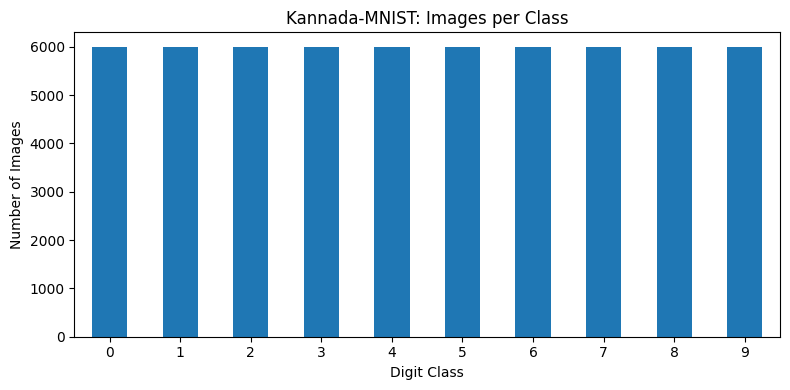

Total training images: 60000
Number of classes: 10
Class counts:
 label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


In [ ]:

import matplotlib.pyplot as plt

class_counts = train_df["label"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
class_counts.plot(kind="bar")
plt.title("Kannada-MNIST: Images per Class")
plt.xlabel("Digit Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Total training images:", len(train_df))
print("Number of classes:", train_df["label"].nunique())
print("Class counts:\n", class_counts)


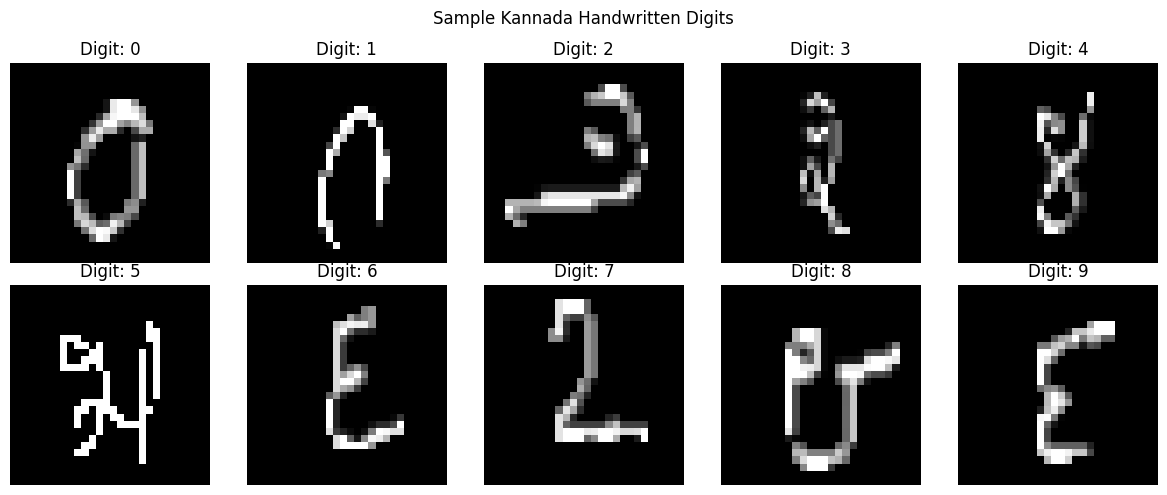

In [ ]:

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for digit, ax in enumerate(axes.flat):
    samples = train_df[train_df["label"] == digit]
    row = samples.iloc[0]

    image = row[pixel_cols].to_numpy(dtype=np.uint8).reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Digit: {digit}")
    ax.axis("off")

plt.suptitle("Sample Kannada Handwritten Digits")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split

X = train_df[pixel_cols].to_numpy(dtype=np.float32)
y = train_df["label"].to_numpy(dtype=np.int64)

# First: reserve 10% for final standard testing
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y,
    test_size=0.10,
    random_state=SEED,
    stratify=y
)

# Then: reserve 1/9 of the remaining 90% for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=1/9,
    random_state=SEED,
    stratify=y_trainval
)

# Normalize and reshape grayscale images
X_train = X_train.reshape(-1, 28, 28, 1) / 255.0
X_val = X_val.reshape(-1, 28, 28, 1) / 255.0
X_test = X_test.reshape(-1, 28, 28, 1) / 255.0

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Held-out test:", X_test.shape, y_test.shape)


Training: (48000, 28, 28, 1) (48000,)
Validation: (6000, 28, 28, 1) (6000,)
Held-out test: (6000, 28, 28, 1) (6000,)


In [ ]:

from tensorflow import keras
from tensorflow.keras import layers

data_augmentation = keras.Sequential([
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomRotation(0.04),
], name="data_augmentation")

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.20),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.35),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,202 (1.79 MB)

 Trainable params: 468,010 (1.79 MB)

 Non-trainable params: 192 (768.00 B)

In [ ]:


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import time

tf.keras.backend.clear_session()

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=3,
    batch_size=256,
    verbose=1
)

print("Training time:", round(time.time() - start, 2), "seconds")


Epoch 1/3
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 74ms/step - accuracy: 0.8721 - loss: 0.4427 - val_accuracy: 0.9738 - val_loss: 0.0961
Epoch 2/3
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 64ms/step - accuracy: 0.9717 - loss: 0.0938 - val_accuracy: 0.9815 - val_loss: 0.0652
Epoch 3/3
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 65ms/step - accuracy: 0.9795 - loss: 0.0670 - val_accuracy: 0.9850 - val_loss: 0.0548
Training time: 39.66 seconds


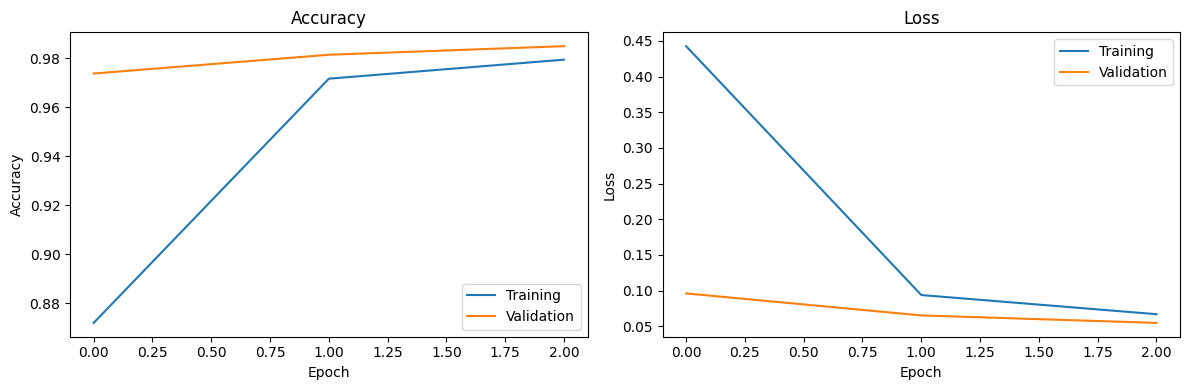

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


Standard test accuracy: 0.9863
Standard test macro F1: 0.9863

Per-class results:
              precision    recall  f1-score   support

           0     0.9816    0.9767    0.9791       600
           1     0.9818    0.9883    0.9850       600
           2     1.0000    0.9983    0.9992       600
           3     0.9916    0.9817    0.9866       600
           4     0.9787    0.9967    0.9876       600
           5     0.9933    0.9883    0.9908       600
           6     0.9613    0.9933    0.9770       600
           7     0.9814    0.9667    0.9740       600
           8     0.9966    0.9900    0.9933       600
           9     0.9983    0.9833    0.9908       600

    accuracy                         0.9863      6000
   macro avg     0.9865    0.9863    0.9863      6000
weighted avg     0.9865    0.9863    0.9863      6000



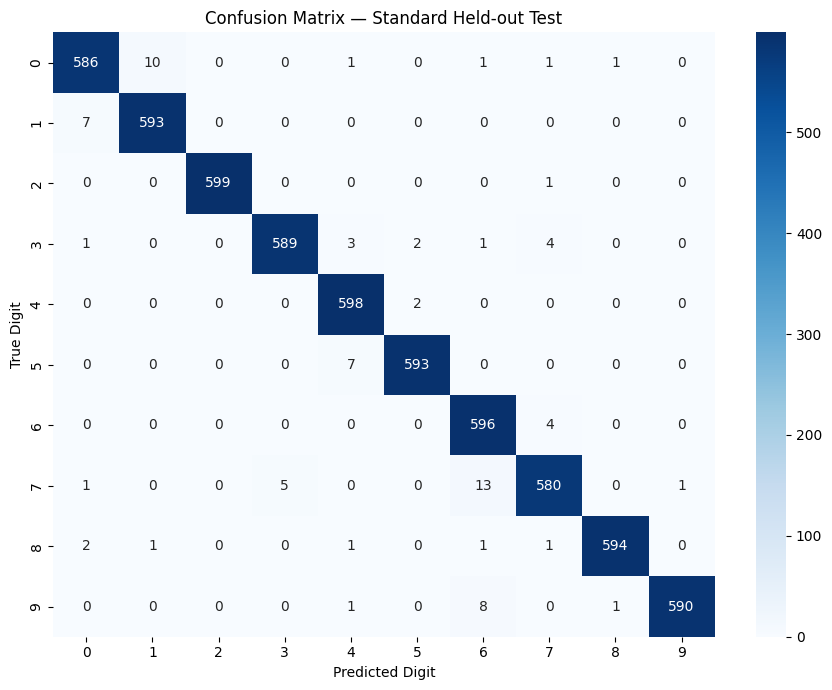

In [ ]:

from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, f1_score
)
import seaborn as sns

test_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(test_probs, axis=1)

print(f"Standard test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Standard test macro F1: {f1_score(y_test, y_pred, average='macro'):.4f}")

print("\nPer-class results:")
print(classification_report(
    y_test, y_pred,
    labels=list(range(10)),
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=list(range(10)))

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix — Standard Held-out Test")
plt.xlabel("Predicted Digit")
plt.ylabel("True Digit")
plt.tight_layout()
plt.show()


Standard test accuracy: 0.9863
Standard test macro F1: 0.9863

Per-class results:
              precision    recall  f1-score   support

           0     0.9816    0.9767    0.9791       600
           1     0.9818    0.9883    0.9850       600
           2     1.0000    0.9983    0.9992       600
           3     0.9916    0.9817    0.9866       600
           4     0.9787    0.9967    0.9876       600
           5     0.9933    0.9883    0.9908       600
           6     0.9613    0.9933    0.9770       600
           7     0.9814    0.9667    0.9740       600
           8     0.9966    0.9900    0.9933       600
           9     0.9983    0.9833    0.9908       600

    accuracy                         0.9863      6000
   macro avg     0.9865    0.9863    0.9863      6000
weighted avg     0.9865    0.9863    0.9863      6000



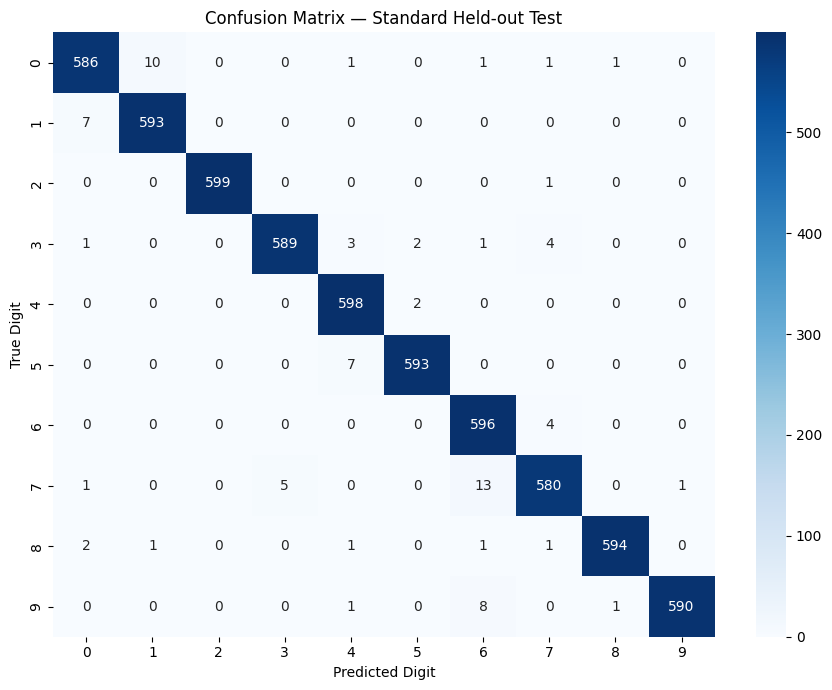

In [ ]:

from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, f1_score
)
import seaborn as sns

test_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(test_probs, axis=1)

print(f"Standard test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Standard test macro F1: {f1_score(y_test, y_pred, average='macro'):.4f}")

print("\nPer-class results:")
print(classification_report(
    y_test, y_pred,
    labels=list(range(10)),
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=list(range(10)))

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix — Standard Held-out Test")
plt.xlabel("Predicted Digit")
plt.ylabel("True Digit")
plt.tight_layout()
plt.show()


Standard test accuracy: 0.9863
Dig-MNIST accuracy:     0.7019
Accuracy drop:          0.2845

Standard test macro F1: 0.9863
Dig-MNIST macro F1:     0.6935

Dig-MNIST per-class report:
              precision    recall  f1-score   support

           0     0.6592    0.3721    0.4757      1024
           1     0.9110    0.6299    0.7448      1024
           2     0.7326    0.8965    0.8063      1024
           3     0.8273    0.4443    0.5781      1024
           4     0.8512    0.7148    0.7771      1024
           5     0.5834    0.9082    0.7105      1024
           6     0.5780    0.6982    0.6325      1024
           7     0.7684    0.6611    0.7108      1024
           8     0.6454    0.8408    0.7303      1024
           9     0.7012    0.8525    0.7695      1024

    accuracy                         0.7019     10240
   macro avg     0.7258    0.7019    0.6935     10240
weighted avg     0.7258    0.7019    0.6935     10240



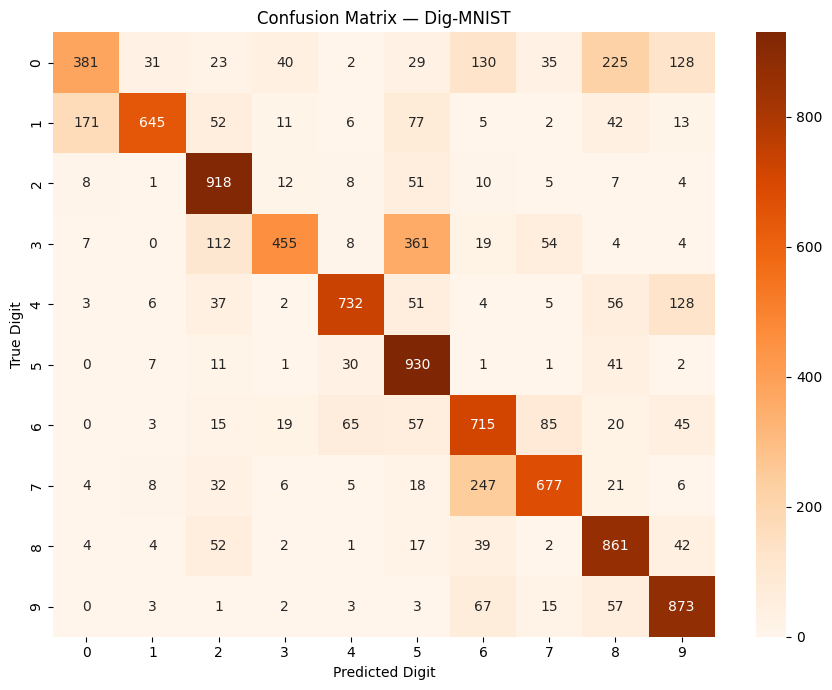

In [ ]:

X_dig = dig_df[pixel_cols].to_numpy(dtype=np.float32)
y_dig = dig_df["label"].to_numpy(dtype=np.int64)

X_dig = X_dig.reshape(-1, 28, 28, 1) / 255.0

dig_probs = model.predict(X_dig, verbose=0)
y_dig_pred = np.argmax(dig_probs, axis=1)

standard_accuracy = accuracy_score(y_test, y_pred)
dig_accuracy = accuracy_score(y_dig, y_dig_pred)

standard_macro_f1 = f1_score(
    y_test, y_pred, average="macro"
)
dig_macro_f1 = f1_score(
    y_dig, y_dig_pred, average="macro"
)

print(f"Standard test accuracy: {standard_accuracy:.4f}")
print(f"Dig-MNIST accuracy:     {dig_accuracy:.4f}")
print(f"Accuracy drop:          {standard_accuracy - dig_accuracy:.4f}")

print(f"\nStandard test macro F1: {standard_macro_f1:.4f}")
print(f"Dig-MNIST macro F1:     {dig_macro_f1:.4f}")

print("\nDig-MNIST per-class report:")
print(classification_report(
    y_dig, y_dig_pred,
    labels=list(range(10)),
    digits=4,
    zero_division=0
))

dig_cm = confusion_matrix(
    y_dig, y_dig_pred,
    labels=list(range(10))
)

plt.figure(figsize=(9, 7))
sns.heatmap(dig_cm, annot=True, fmt="d", cmap="Oranges")
plt.title("Confusion Matrix — Dig-MNIST")
plt.xlabel("Predicted Digit")
plt.ylabel("True Digit")
plt.tight_layout()
plt.show()


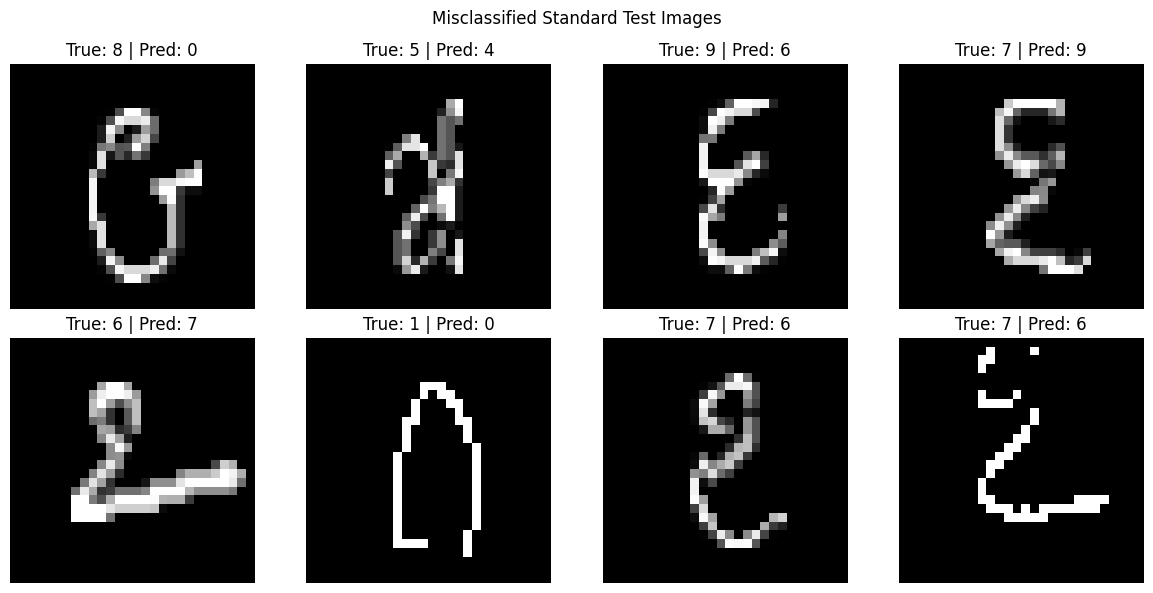

In [ ]:

wrong_indices = np.where(y_test != y_pred)[0]

if len(wrong_indices) == 0:
    print("No misclassified standard test images were found.")
else:
    n_show = min(8, len(wrong_indices))
    selected = wrong_indices[:n_show]

    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, idx in zip(axes, selected):
        ax.imshow(X_test[idx].squeeze(), cmap="gray")
        ax.set_title(
            f"True: {y_test[idx]} | Pred: {y_pred[idx]}"
        )
        ax.axis("off")

    plt.suptitle("Misclassified Standard Test Images")
    plt.tight_layout()
    plt.show()


,Dataset,Accuracy,Macro F1,Images evaluated
0,Standard held-out test,0.9863,0.9863,6000
1,Dig-MNIST,0.7019,0.6935,10240


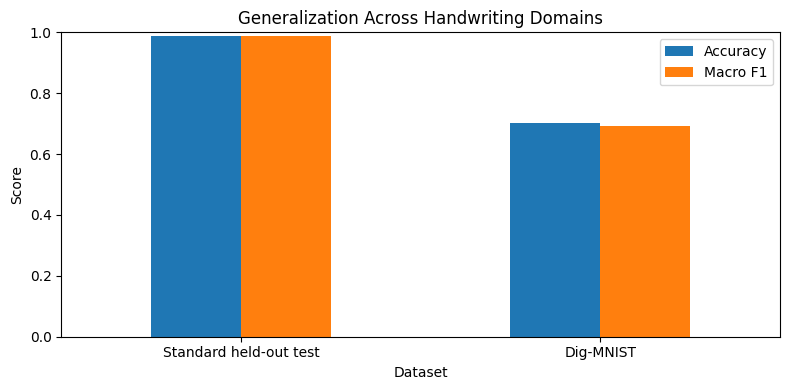

In [ ]:

comparison = pd.DataFrame({
    "Dataset": ["Standard held-out test", "Dig-MNIST"],
    "Accuracy": [standard_accuracy, dig_accuracy],
    "Macro F1": [standard_macro_f1, dig_macro_f1],
    "Images evaluated": [len(y_test), len(y_dig)]
})

display(comparison.round(4))

comparison.set_index("Dataset")[["Accuracy", "Macro F1"]].plot(
    kind="bar", figsize=(8, 4), ylim=(0, 1)
)
plt.title("Generalization Across Handwriting Domains")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

model.save("PS41_Kannada_CNN.keras")
comparison.to_csv("PS41_domain_shift_results.csv", index=False)

print("Saved model and comparison results.")


Saved model and comparison results.
